# Assignment 1 solution
This document covers the solutions, proposed by Nelson Wiltebo and Jakub 
Zabramski, of the tasks described in assignment 1.

**Statement of AI use:** AI was used in order to understand how the ``set_ylim``
method works. It was at times also used to debug errors, and to understand how
notebooks work when using declarations from other cells.

## Task 1

### a)

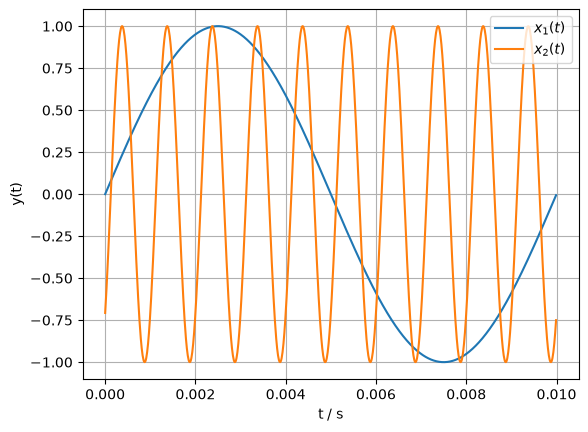

In [105]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

dt = 0.01 * 10 ** -3

t = np.arange(0, 10 * 10 ** -3, dt)

T_1 = 0.01
A_1 = 1
fi_1 = 0
w_1 = 2 * np.pi / T_1

x_1 = A_1 * np.sin(w_1 * t + fi_1)

A_2 = 1
fi_2 = - np.pi / 4
f_2 = 1000
w_2 = 2 * np.pi * f_2

x_2 = A_2 * np.sin(w_2 * t + fi_2)

fig, ax = plt.subplots()
ax.grid()

ax.set_xlabel('t / s')
ax.set_ylabel('y(t)')

ax.plot(t, x_1, label="$x_1(t)$")
ax.plot(t, x_2, label="$x_2(t)$")
ax.legend()

### b)

The first sound produced by the $x_1(t)$ signal sounds like it is produced by an 
electronic bass

The second sound produced by the $x_2(t)$ signal resembles the sound an old phone
makes when it's off the hook

In [106]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

t = np.arange(0, 5, dt)

x_1 = A_1 * np.sin(w_1 * t + fi_1)
x_2 = A_2 * np.sin(w_2 * t + fi_2)

sd.play(x_1, 1 / dt, blocking='True')
sd.play(x_2, 1 / dt, blocking='True')

## Task 2
### a)

In [107]:
import numpy as np
import matplotlib as plt
from scipy import signal
import sounddevice as sd

def convolve(x, h):
    y = dt * signal.convolve(x, h, method='direct')
    y = y[0:x.shape[0]]
    return y

### b)

The output $y(t)$ is the same as the impulse response $h(t)$ because the definiton of 
the impulse response says that when the input $x(t)$ is the dirac delta 
function, then the output will be the impulse response function.

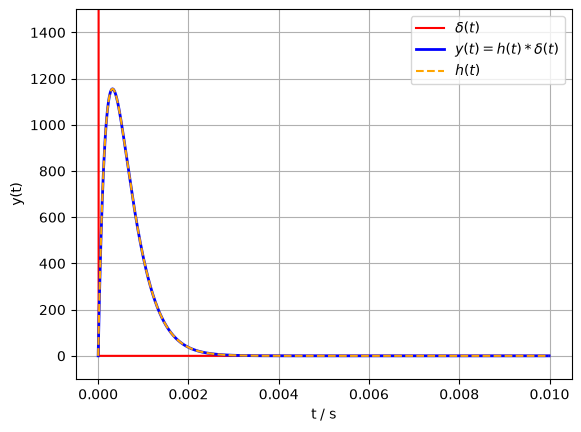

In [108]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

t2 = np.arange(0, 10 * 10 ** -3, dt)

alpha = 1000 * np.pi

impulse_response = alpha ** 2 * t2 * np.exp(-alpha * t2) # u(t) is never zero since t2 is 
                                            # always non-negative

d = np.zeros(t2.shape)
d[0] = 1 / dt

fig, ax = plt.subplots()
ax.grid()

ax.set_xlabel('t / s')
ax.set_ylabel('y(t)')
ax.set_ylim(-100, 1500)

ax.plot(t2, d, label='$δ(t)$', color='red')

y = convolve(d, impulse_response)
ax.plot(t2, y, label='$y(t) = h(t) * δ(t)$', color='blue', linewidth=2)

ax.plot(t2, impulse_response, label='$h(t)$', linestyle='--', color='orange')

ax.legend()

### c)

The system affects signals with high frequencies more than signals with low 
frequencies, i.e a low-pass filter. We can see this in the graph where $y_2(t)$ is
the output when $x_2(t)$, which has a frequency of 1000 Hz, is the input. $y_2(t)$ has a
much smaller amplitude compared to $x_2(t)$. However, $y_1(t)$ is mostly unchanged, 
which coincises with a low-pass filter considering $x_1(t)$ has a frequency of:

$$
\frac{1}{T_1} = \frac{1}{0.01} = 100\:\text{Hz}
$$

However we can observe that the outputs' phase shift is
different compared to the inputs', but the frequencies of the outputs remain
unchanged, as expected considering the sine-in sine-out principle.

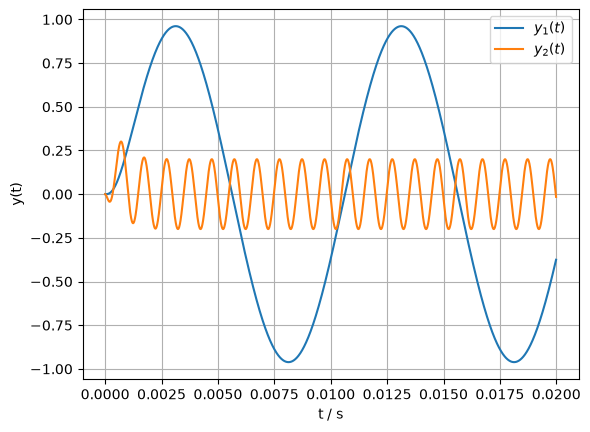

In [109]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

t3 = np.arange(0, 20 * 10 ** -3, dt)

x_1 = A_1 * np.sin(w_1 * t3 + fi_1)
x_2 = A_2 * np.sin(w_2 * t3 + fi_2)

y_1 = convolve(x_1, impulse_response)
y_2 = convolve(x_2, impulse_response)

fig, ax = plt.subplots()
ax.grid()

ax.set_xlabel('t / s')
ax.set_ylabel('y(t)')

ax.plot(t3, y_1, label="$y_1(t)$")
ax.plot(t3, y_2, label="$y_2(t)$")
ax.legend()



### d)

$x_3(t)$ is the sum of two sine signals, and those the inherits properties from
both of the signals, which explains the wave-on-wave look. Because $x_3(t)$ is
the sum of two sine signals, the sine-in sine-out principle does not apply. 
However, we can observe that the output $y_3(t)$ retains the amplitude of the
low frequency signal $x_1(t)$, while the amplitude of the high frequency signal
$x_2(t)$ is reduced. We can also observe a phase shift.

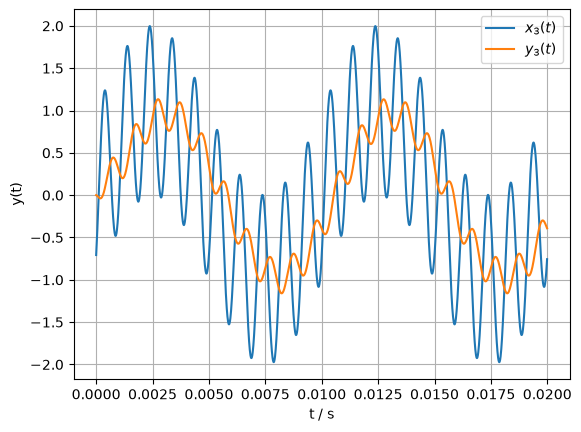

In [110]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

x_3 = x_1 + x_2

y_3 = convolve(x_3, impulse_response)

fig, ax = plt.subplots()
ax.grid()

ax.set_xlabel('t / s')
ax.set_ylabel('y(t)')

ax.plot(t3, x_3, label="$x_3(t)$")
ax.plot(t3, y_3, label="$y_3(t)$")
ax.legend()